# EDA v2 — Chl-a Spatio-Temporal (Selat Sunda)

Notebook ini menjawab dua hal:

1. **Inventaris data**: berapa grid dan berapa observasi pada tiap tahap (grid kandidat → harian → bulanan → panel model).
2. **Layak atau tidak**: seberapa banyak variasi chl-a yang *tersisa untuk diprediksi* setelah musiman dihitung, apakah anomalinya punya struktur spasial/temporal, apakah eksogen membantu, dan seberapa baik baseline sederhana.

Notebook ini diparameterisasi (`REGION`, `TAG`, jalur file). Untuk Laut Jawa barat, ubah sel konfigurasi lalu jalankan ulang semuanya. Hasil ringkas tersimpan di `scorecard_<REGION>_<TAG>.csv` sehingga kedua lokasi bisa dibandingkan berdampingan.

Semua anomali memakai klimatologi dari **periode train saja** (`TRAIN_END`), supaya tidak ada kebocoran data ke periode uji.

## 0. Konfigurasi dan pemuatan data

In [1]:
import os
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

warnings.filterwarnings('ignore', category=RuntimeWarning)
pd.set_option('display.width', 170)
pd.set_option('display.max_columns', 40)
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.25})

# ------------------ KONFIGURASI (ubah di sini saat pindah lokasi) ------------------
REGION = 'selat_sunda'
TAG = '200301_202512_v1'
ROOT = Path(os.environ.get('THESIS_ROOT', r'D:/thesis'))

CHLA_DIR = ROOT / 'data' / 'processed' / 'chla'
GRID_CSV = ROOT / 'data' / 'metadata' / 'output_grid_target.csv'
MONTHLY_PATH = CHLA_DIR / f'chla_monthly_{TAG}.csv'
PANEL_PATH = ROOT / 'data' / 'processed' / 'model_dataset' / f'{REGION}_monthly_panel_{TAG}.csv'
TABLE_DIR = ROOT / 'output' / 'tables'
FIGURE_DIR = ROOT / 'output' / 'figures'

TRAIN_END = pd.Timestamp('2018-12-01')   # train s.d. bulan ini, uji sesudahnya
MIN_COVER = 0.25                         # fraksi piksel valid minimum agar grid-bulan dianggap "reliable"
H = 1                                    # horizon forecast (bulan)
GRID_DEG = 0.25
EXOG = {'sst_c': 'SST', 'u10_m_s': 'u10', 'v10_m_s': 'v10', 'wind_speed_m_s': 'Kec. angin'}
# -----------------------------------------------------------------------------------

TABLE_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
score = {}   # diisi sepanjang notebook, disimpan di akhir sebagai scorecard

def save_fig(fig, name):
    fig.savefig(FIGURE_DIR / f'{name}_{REGION}_{TAG}.png', dpi=200, bbox_inches='tight')

def save_table(df, name, index=True):
    df.to_csv(TABLE_DIR / f'{name}_{REGION}_{TAG}.csv', index=index, encoding='utf-8-sig')

if not MONTHLY_PATH.is_file():
    raise FileNotFoundError(f'File bulanan tidak ditemukan: {MONTHLY_PATH}')

m = pd.read_csv(MONTHLY_PATH, parse_dates=['month'], dtype={'grid_id': str}, encoding='utf-8-sig')
m = m.sort_values(['grid_id', 'month']).reset_index(drop=True)
assert not m.duplicated(['month', 'grid_id']).any(), 'Ada month-grid_id duplikat.'
assert len(m) == m.grid_id.nunique() * m.month.nunique(), 'Panel tidak seimbang.'

m['cal_month'] = m.month.dt.month
m['reliable'] = m.chla_mg_m3.notna() & (m.valid_pixel_fraction >= MIN_COVER)
m['y'] = np.where(m.reliable, np.log10(m.chla_mg_m3), np.nan)   # target: log10 chl-a, hanya grid-bulan reliable

# Eksogen (opsional): dibaca dari panel model
exog_ok = False
if PANEL_PATH.is_file():
    px = pd.read_csv(PANEL_PATH, usecols=['month', 'grid_id', *EXOG], parse_dates=['month'],
                     dtype={'grid_id': str}, encoding='utf-8-sig')
    m = m.merge(px, on=['month', 'grid_id'], how='left')
    exog_ok = all(m[c].notna().mean() > 0.5 for c in EXOG)
print('Eksogen dimuat:', exog_ok, '| file panel:', PANEL_PATH)

grid_info = m.groupby('grid_id', as_index=False).agg(lon=('lon', 'first'), lat=('lat', 'first'))
grid_info[['lon', 'lat']] = grid_info[['lon', 'lat']].round(3)

def grid_map(ax, values, title, cmap='viridis', label='', vmin=None, vmax=None):
    # peta grid reguler; values = Series berindeks grid_id
    d = grid_info.assign(v=grid_info.grid_id.map(values))
    lons = np.round(np.arange(d.lon.min(), d.lon.max() + GRID_DEG / 2, GRID_DEG), 3)
    lats = np.round(np.arange(d.lat.min(), d.lat.max() + GRID_DEG / 2, GRID_DEG), 3)
    z = d.pivot(index='lat', columns='lon', values='v').reindex(index=lats, columns=lons)
    xe = np.append(lons - GRID_DEG / 2, lons[-1] + GRID_DEG / 2)
    ye = np.append(lats - GRID_DEG / 2, lats[-1] + GRID_DEG / 2)
    mesh = ax.pcolormesh(xe, ye, z.to_numpy(), cmap=cmap, vmin=vmin, vmax=vmax)
    ax.figure.colorbar(mesh, ax=ax, label=label, shrink=0.85)
    ax.set_title(title, fontsize=10)
    ax.set_xlabel('Bujur'); ax.set_ylabel('Lintang')
    ax.set_aspect('equal', adjustable='box'); ax.grid(False)

Eksogen dimuat: True | file panel: D:\thesis\data\processed\model_dataset\selat_sunda_monthly_panel_200301_202512_v1.csv


## 1. Inventaris data: berapa grid dan berapa data pada tiap tahap

Tabel di bawah membaca file apa pun yang ada di `CHLA_DIR` dan melaporkan yang tidak ditemukan. Tahap **harian** hanya terisi kalau file `chla_daily_*.csv` hasil `scrape_chla_v4.py` masih ada.

In [2]:
rows = []

# Tahap 0: grid kandidat dari Rmd
if GRID_CSV.is_file():
    ga = pd.read_csv(GRID_CSV, dtype={'grid_id': str}, encoding='utf-8-sig')
    if 'selected' in ga:
        sel = ga['selected'].astype(str).str.lower().str.strip().isin(['true', '1'])
    else:
        sel = pd.Series(True, index=ga.index)
    rows.append({'tahap': '0. Grid kandidat (Rmd)', 'grid': len(ga), 'periode': '-', 'unit_waktu': '-',
                 'baris': len(ga), 'catatan': f'terpilih (selected) = {int(sel.sum())}, tidak terpilih = {int((~sel).sum())}'})
else:
    rows.append({'tahap': '0. Grid kandidat (Rmd)', 'grid': np.nan, 'periode': '-', 'unit_waktu': '-',
                 'baris': np.nan, 'catatan': f'file tidak ditemukan: {GRID_CSV}'})

# Tahap 1: harian per grid 0.25 derajat
daily_files = sorted(CHLA_DIR.glob('chla_daily_*.csv'))
daily_detail = None
if daily_files:
    wanted = {'date', 'grid_id', 'chla_mg_m3', 'n_valid_pixels', 'n_pixels_total', 'source_status'}
    d = pd.concat([pd.read_csv(f, usecols=lambda c: c in wanted, parse_dates=['date'],
                               dtype={'grid_id': str}, encoding='utf-8-sig') for f in daily_files])
    d = d.drop_duplicates(['date', 'grid_id'], keep='last')
    ndays_cal = (d.date.max() - d.date.min()).days + 1
    n_g = d.grid_id.nunique()
    cover_d = (d.n_valid_pixels / d.n_pixels_total) if {'n_valid_pixels', 'n_pixels_total'} <= set(d.columns) else None
    rows.append({'tahap': '1. Harian (grid 0.25°)', 'grid': n_g,
                 'periode': f'{d.date.min():%Y-%m-%d} s.d. {d.date.max():%Y-%m-%d}',
                 'unit_waktu': f'{d.date.nunique():,} hari (kalender: {ndays_cal:,})',
                 'baris': len(d),
                 'catatan': f'baris harapan {n_g * ndays_cal:,}; chl-a valid {d.chla_mg_m3.notna().mean():.1%} grid-hari; {len(daily_files)} file'})
    daily_detail = {
        'status sumber (hari)': d.drop_duplicates('date').source_status.value_counts().to_dict() if 'source_status' in d else {},
        'grid-hari dengan >=1 piksel valid': float(d.chla_mg_m3.notna().mean()),
        'rata-rata fraksi piksel valid': float(cover_d.mean()) if cover_d is not None else np.nan,
    }
else:
    rows.append({'tahap': '1. Harian (grid 0.25°)', 'grid': np.nan, 'periode': '-', 'unit_waktu': '-', 'baris': np.nan,
                 'catatan': f'tidak ada chla_daily_*.csv di {CHLA_DIR}'})

# Tahap 2: bulanan
n_cell = len(m)
rows.append({'tahap': '2. Bulanan (grid 0.25°)', 'grid': m.grid_id.nunique(),
             'periode': f'{m.month.min():%Y-%m} s.d. {m.month.max():%Y-%m}',
             'unit_waktu': f'{m.month.nunique()} bulan', 'baris': n_cell,
             'catatan': f'chl-a tidak NaN {m.chla_mg_m3.notna().sum():,} ({m.chla_mg_m3.notna().mean():.1%}); '
                        f'reliable (>= {MIN_COVER:.0%} piksel) {m.reliable.sum():,} ({m.reliable.mean():.1%})'})

# Tahap 3: panel model (eksogen)
if exog_ok:
    rows.append({'tahap': '3. Panel model (+ eksogen)', 'grid': m.grid_id.nunique(),
                 'periode': f'{m.month.min():%Y-%m} s.d. {m.month.max():%Y-%m}',
                 'unit_waktu': f'{m.month.nunique()} bulan', 'baris': n_cell,
                 'catatan': 'eksogen: ' + ', '.join(EXOG) + f' (lengkap {m[list(EXOG)].notna().all(axis=1).mean():.1%})'})

inventory = pd.DataFrame(rows)
display(inventory)
if daily_detail:
    print('Detail harian:', daily_detail)
save_table(inventory, 'inventaris_data', index=False)

,tahap,grid,periode,unit_waktu,baris,catatan
0,0. Grid kandidat (Rmd),148.0,-,-,148.0,"terpilih (selected) = 148, tidak terpilih = 0"
1,1. Harian (grid 0.25°),NaN,-,-,NaN,tidak ada chla_daily_*.csv di D:\thesis\data\p...
2,2. Bulanan (grid 0.25°),148.0,2003-01 s.d. 2025-12,276 bulan,40848.0,"chl-a tidak NaN 39,711 (97.2%); reliable (>= 2..."
3,3. Panel model (+ eksogen),148.0,2003-01 s.d. 2025-12,276 bulan,40848.0,"eksogen: sst_c, u10_m_s, v10_m_s, wind_speed_m..."


## 2. Karakteristik data: cakupan, resolusi, distribusi

Chl-a hampir selalu miring ke kanan, jadi seluruh analisis berikutnya memakai **log10(chl-a)**.

,nilai
Jumlah grid,148
Ukuran grid (derajat),0.25
Bujur,103.125 s.d. 106.875 BT
Lintang,-7.875 s.d. -5.125 LS/LU
Bounding box (kolom x baris),16 x 12 = 192 sel; terisi 148 (77%)
Piksel sumber per grid (median),36
Jumlah bulan,276
Total grid-bulan,40848


,chla_mg_m3
count,39711.000
mean,0.479
std,0.769
min,0.030
5%,0.081
25%,0.129
50%,0.214
75%,0.538
95%,1.705
99%,3.521


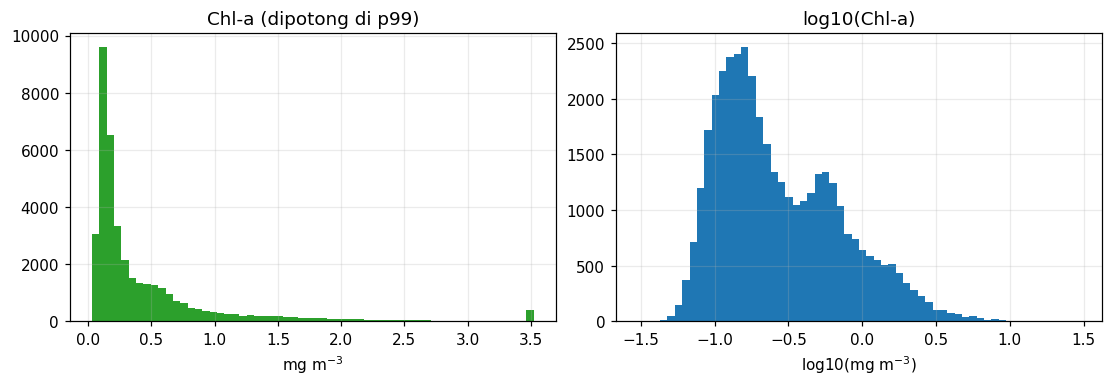

In [3]:
n_lon, n_lat = grid_info.lon.nunique(), grid_info.lat.nunique()
spatial = pd.Series({
    'Jumlah grid': len(grid_info),
    'Ukuran grid (derajat)': GRID_DEG,
    'Bujur': f'{grid_info.lon.min()} s.d. {grid_info.lon.max()} BT',
    'Lintang': f'{grid_info.lat.min()} s.d. {grid_info.lat.max()} LS/LU',
    'Bounding box (kolom x baris)': f'{n_lon} x {n_lat} = {n_lon * n_lat} sel; terisi {len(grid_info)} ({len(grid_info) / (n_lon * n_lat):.0%})',
    'Piksel sumber per grid (median)': int(m.n_pixels_total.median()),
    'Jumlah bulan': m.month.nunique(),
    'Total grid-bulan': len(m),
})
display(spatial.to_frame('nilai'))

x = m.chla_mg_m3.dropna()
stats = x.describe(percentiles=[.05, .25, .5, .75, .95, .99]).to_frame('chla_mg_m3')
stats.loc['skewness'] = x.skew()
stats.loc['skewness (log10)'] = np.log10(x).skew()
display(stats.round(3))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.4), constrained_layout=True)
axes[0].hist(x.clip(upper=x.quantile(.99)), bins=60, color='tab:green'); axes[0].set_title('Chl-a (dipotong di p99)')
axes[0].set_xlabel('mg m$^{-3}$')
axes[1].hist(np.log10(x), bins=60, color='tab:blue'); axes[1].set_title('log10(Chl-a)')
axes[1].set_xlabel('log10(mg m$^{-3}$)')
save_fig(fig, 'distribusi_chla'); plt.show()

## 3. Availability: apa yang disembunyikan angka 97%

`chla_observed` = minimal 1 dari 36 piksel valid. Di bawah ini ketersediaan dihitung dengan beberapa ambang fraksi piksel valid, lalu pola musiman, konsentrasi pada bulan tertentu, panjang celah per grid, dan hubungannya dengan kadar chl-a.

,syarat,n_tersedia,ketersediaan
0,>= 1 piksel (definisi lama),39711,97.2%
1,>= 10% piksel valid,39476,96.6%
2,>= 25% piksel valid,38803,95.0%
3,>= 50% piksel valid,37409,91.6%
4,>= 75% piksel valid,34910,85.5%


Grid-bulan "tersedia" tetapi hanya 1-6 piksel: 688 (1.7%)

Bulan dengan ketersediaan < 90%: 24 dari 276; menyumbang 823 dari 1,137 NaN (72%)


,n_grid,n_nan,cover,avail
month,,,,
2008-02-01,148,95,0.139,0.358
2010-11-01,148,69,0.195,0.534
2015-10-01,148,62,0.351,0.581
2022-12-01,148,52,0.282,0.649
2008-11-01,148,47,0.349,0.682
2016-10-01,148,46,0.365,0.689
2018-01-01,148,46,0.375,0.689
2024-12-01,148,45,0.353,0.696
2021-01-01,148,44,0.353,0.703


,nan_rate,cover_lt50,mean_cover
cal_month,,,
1,0.036,0.107,0.868
2,0.043,0.110,0.868
3,0.002,0.021,0.955
4,0.001,0.006,0.972
5,0.000,0.002,0.979
6,0.000,0.004,0.978
7,0.000,0.002,0.978
8,0.002,0.014,0.963
9,0.008,0.049,0.913


,n_grid
celah_terpanjang_bulan,
1,98
2,45
3,3
4,2



Grid dengan piksel valid maksimum < 36 (indikasi daratan/maskir tetap): 11
Korelasi (cakupan rata-rata grid, log rata-rata chl-a): -0.561


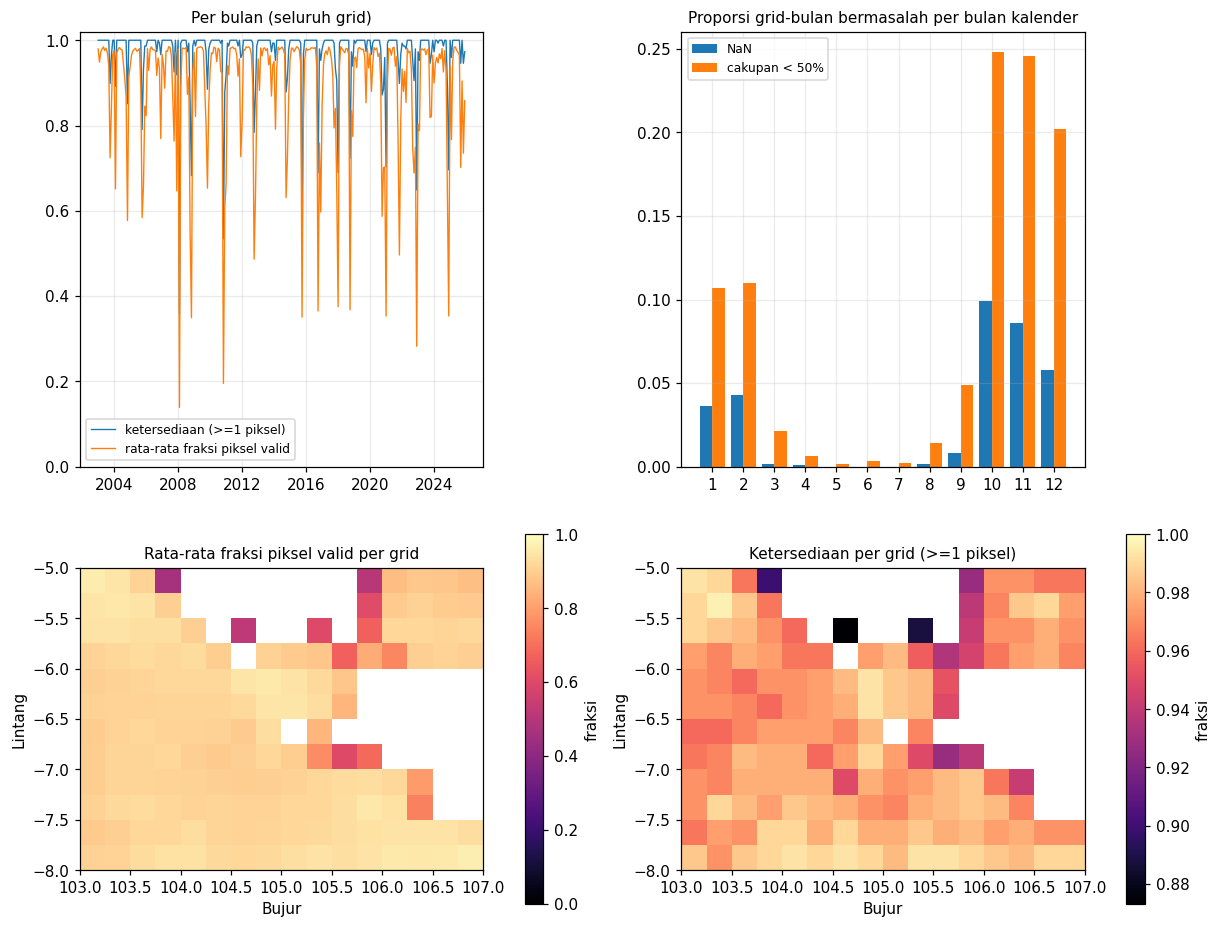

In [4]:
rows = []
for t in [0, .1, .25, .5, .75]:
    ok = m.chla_mg_m3.notna() if t == 0 else (m.chla_mg_m3.notna() & (m.valid_pixel_fraction >= t))
    rows.append({'syarat': '>= 1 piksel (definisi lama)' if t == 0 else f'>= {t:.0%} piksel valid',
                 'n_tersedia': int(ok.sum()), 'ketersediaan': ok.mean()})
thr = pd.DataFrame(rows)
display(thr.assign(ketersediaan=thr.ketersediaan.map('{:.1%}'.format)))
few = int(((m.n_valid_pixels > 0) & (m.n_valid_pixels <= 6)).sum())
print(f'Grid-bulan "tersedia" tetapi hanya 1-6 piksel: {few:,} ({few / len(m):.1%})')
score['avail_ge1px'] = m.chla_mg_m3.notna().mean()
score['avail_ge50pct_px'] = (m.chla_mg_m3.notna() & (m.valid_pixel_fraction >= .5)).mean()
score['avail_reliable'] = m.reliable.mean()

# per bulan (seluruh wilayah)
mo = m.groupby('month').agg(n_grid=('grid_id', 'size'), n_nan=('chla_mg_m3', lambda s: int(s.isna().sum())),
                            cover=('valid_pixel_fraction', 'mean'))
mo['avail'] = 1 - mo.n_nan / mo.n_grid
bad = mo[mo.avail < 0.9]
print(f'\nBulan dengan ketersediaan < 90%: {len(bad)} dari {len(mo)}; menyumbang '
      f'{bad.n_nan.sum():,} dari {mo.n_nan.sum():,} NaN ({bad.n_nan.sum() / max(mo.n_nan.sum(), 1):.0%})')
display(mo.sort_values('avail').head(10).assign(avail=lambda d: d.avail.round(3), cover=lambda d: d.cover.round(3)))
score['n_bulan_avail_lt90'] = len(bad)

# per bulan kalender
cal = m.groupby('cal_month').agg(nan_rate=('chla_mg_m3', lambda s: s.isna().mean()),
                                 cover_lt50=('valid_pixel_fraction', lambda s: (s < .5).mean()),
                                 mean_cover=('valid_pixel_fraction', 'mean'))
display(cal.round(3))

# celah beruntun per grid
def max_run(a):
    best = run = 0
    for v in a:
        run = run + 1 if v else 0
        best = max(best, run)
    return best
gaps = m.groupby('grid_id').chla_mg_m3.apply(lambda s: max_run(s.isna().to_numpy()))
display(gaps.value_counts().sort_index().rename_axis('celah_terpanjang_bulan').to_frame('n_grid'))

# per grid
ga_ = m.groupby('grid_id').agg(avail=('chla_mg_m3', lambda s: s.notna().mean()),
                               cover=('valid_pixel_fraction', 'mean'),
                               max_valid_px=('n_valid_pixels', 'max'),
                               mean_chla=('chla_mg_m3', 'mean'))
print(f'\nGrid dengan piksel valid maksimum < {int(m.n_pixels_total.median())} (indikasi daratan/maskir tetap): '
      f'{int((ga_.max_valid_px < m.n_pixels_total.median()).sum())}')
print('Korelasi (cakupan rata-rata grid, log rata-rata chl-a):',
      round(float(np.corrcoef(ga_.cover, np.log(ga_.mean_chla))[0, 1]), 3))
save_table(ga_, 'availability_per_grid')

fig, axes = plt.subplots(2, 2, figsize=(11, 8.5), constrained_layout=True)
axes[0, 0].plot(mo.index, mo.avail, label='ketersediaan (>=1 piksel)', lw=.9)
axes[0, 0].plot(mo.index, mo.cover, label='rata-rata fraksi piksel valid', lw=.9)
axes[0, 0].set_ylim(0, 1.02); axes[0, 0].legend(fontsize=8); axes[0, 0].set_title('Per bulan (seluruh grid)', fontsize=10)
w = .4
axes[0, 1].bar(cal.index - w / 2, cal.nan_rate, w, label='NaN'); axes[0, 1].bar(cal.index + w / 2, cal.cover_lt50, w, label='cakupan < 50%')
axes[0, 1].set_xticks(range(1, 13)); axes[0, 1].legend(fontsize=8); axes[0, 1].set_title('Proporsi grid-bulan bermasalah per bulan kalender', fontsize=10)
grid_map(axes[1, 0], ga_.cover, 'Rata-rata fraksi piksel valid per grid', 'magma', 'fraksi', 0, 1)
grid_map(axes[1, 1], ga_.avail, 'Ketersediaan per grid (>=1 piksel)', 'magma', 'fraksi', ga_.avail.min(), 1)
save_fig(fig, 'availability'); plt.show()

## 4. Persiapan: anomali dengan klimatologi dari periode train

`y` = log10 chl-a (hanya grid-bulan *reliable*). Anomali = `y` dikurangi rata-rata per (grid, bulan kalender) yang dihitung dari bulan ≤ `TRAIN_END`. Eksogen diperlakukan sama.

In [5]:
def add_anomaly(frame, col, anom_name, clim_name):
    frame = frame.drop(columns=[anom_name, clim_name], errors='ignore')
    clim = (frame.loc[frame.month <= TRAIN_END].groupby(['grid_id', 'cal_month'])[col].mean()
            .rename(clim_name).reset_index())
    frame = frame.merge(clim, on=['grid_id', 'cal_month'], how='left')
    frame[anom_name] = frame[col] - frame[clim_name]
    return frame

m = add_anomaly(m, 'y', 'anom', 'y_clim')
if exog_ok:
    for c in EXOG:
        m = add_anomaly(m, c, f'{c}_anom', f'{c}_clim')

m = m.sort_values(['grid_id', 'month']).reset_index(drop=True)
A = m.pivot(index='month', columns='grid_id', values='anom')   # matriks bulan x grid
n_train_m = int((m.month.drop_duplicates() <= TRAIN_END).sum())
print(f'Train: {n_train_m} bulan (s.d. {TRAIN_END:%Y-%m}); uji: {m.month.nunique() - n_train_m} bulan')
print(f'Sel anomali tersedia: {m.anom.notna().sum():,} dari {len(m):,}')

Train: 192 bulan (s.d. 2018-12); uji: 84 bulan
Sel anomali tersedia: 38,803 dari 40,848


## 5. Peta spasial: bukan hanya rata-rata

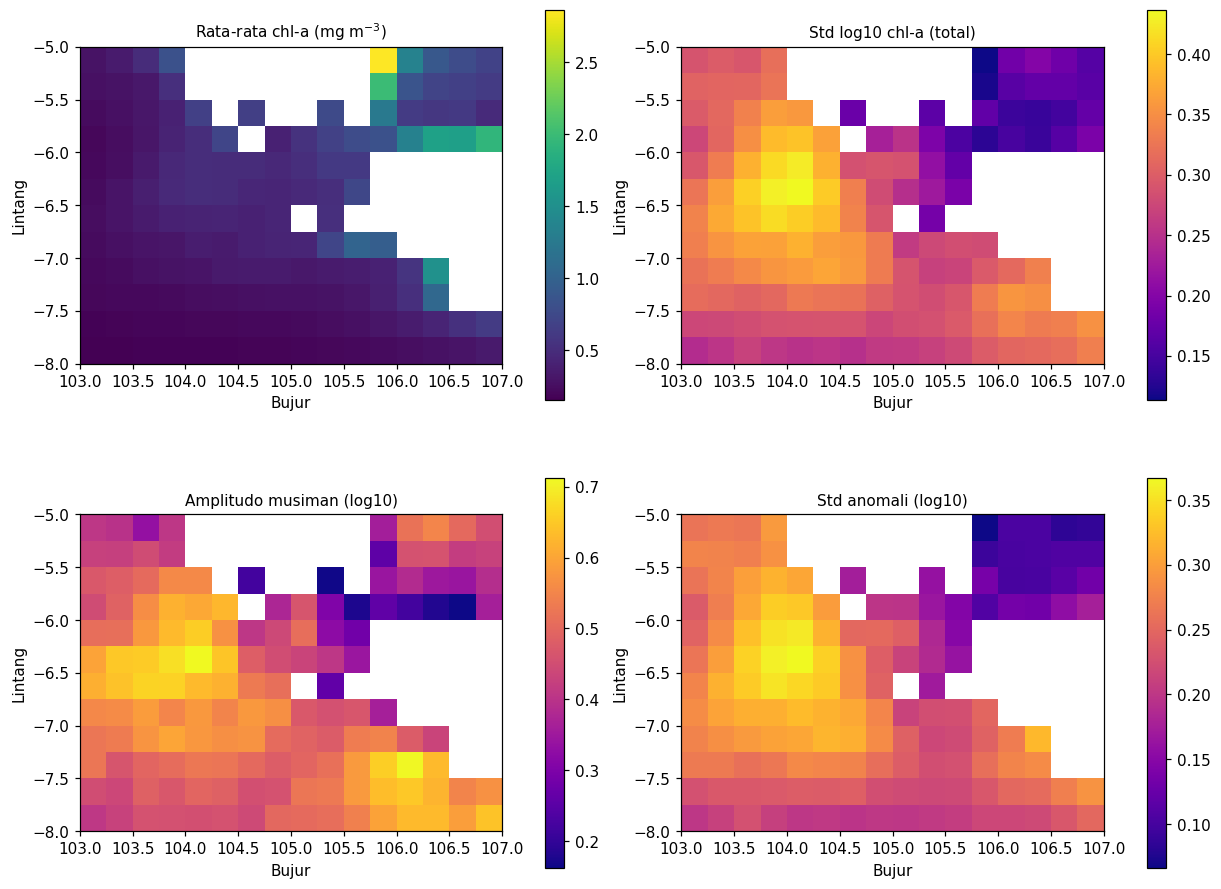

Grid dengan rata-rata chl-a > 1 mg/m3: 11 | median antar grid: 0.364


In [6]:
gm = m.groupby('grid_id')
amp = m.groupby(['grid_id', 'cal_month']).y.mean().groupby('grid_id').agg(lambda s: s.max() - s.min())
maps = {
    'Rata-rata chl-a (mg m$^{-3}$)': gm.chla_mg_m3.mean(),
    'Std log10 chl-a (total)': gm.y.std(),
    'Amplitudo musiman (log10)': amp,
    'Std anomali (log10)': gm.anom.std(),
}
fig, axes = plt.subplots(2, 2, figsize=(11, 8.5), constrained_layout=True)
for ax, (title, ser), cmap in zip(axes.ravel(), maps.items(), ['viridis', 'plasma', 'plasma', 'plasma']):
    grid_map(ax, ser, title, cmap)
save_fig(fig, 'peta_spasial'); plt.show()

grid_stats = pd.DataFrame(maps)
save_table(grid_stats, 'ringkasan_spasial_per_grid')
print('Grid dengan rata-rata chl-a > 1 mg/m3:', int((grid_stats.iloc[:, 0] > 1).sum()),
      '| median antar grid:', round(float(grid_stats.iloc[:, 0].median()), 3))

## 6. Dekomposisi varians log10 chl-a

Seberapa besar varians berasal dari (a) beda antar-grid, (b) siklus musiman per grid, (c) **anomali** — bagian yang benar-benar perlu diprediksi?

Dilakukan untuk semua grid dan per tercile rata-rata chl-a grid (untuk melihat apakah grid pesisir dan lepas pantai berbeda). **Kalau porsi anomali kecil, ruang model untuk mengalahkan klimatologi sempit di lokasi mana pun.**

In [7]:
def decompose(d):
    d = d.dropna(subset=['y'])
    tot = d.y.var()
    gmean = d.groupby('grid_id').y.transform('mean')
    gcm = d.groupby(['grid_id', 'cal_month']).y.transform('mean')
    return pd.Series({'antar-grid': gmean.var() / tot, 'musiman': (gcm - gmean).var() / tot,
                      'anomali (sisa)': (d.y - gcm).var() / tot,
                      'std anomali (log10)': (d.y - gcm).std(), 'n_obs': len(d)})

gmean_y = m.groupby('grid_id').y.mean()
grp = pd.qcut(gmean_y, 3, labels=['chl-a rendah', 'chl-a menengah', 'chl-a tinggi'])
m['grp'] = m.grid_id.map(grp)

dec = pd.concat({'semua grid': decompose(m), **{str(k): decompose(m[m.grp == k]) for k in grp.cat.categories}}, axis=1).T
display(dec.round(3))
save_table(dec, 'dekomposisi_varians')
score['var_antar_grid'] = float(dec.loc['semua grid', 'antar-grid'])
score['var_musiman'] = float(dec.loc['semua grid', 'musiman'])
score['var_anomali'] = float(dec.loc['semua grid', 'anomali (sisa)'])
score['std_anomali_log10'] = float(dec.loc['semua grid', 'std anomali (log10)'])

,antar-grid,musiman,anomali (sisa),std anomali (log10),n_obs
semua grid,0.485,0.160,0.355,0.249,38803.0
chl-a rendah,0.015,0.293,0.692,0.258,12961.0
chl-a menengah,0.043,0.299,0.658,0.285,12949.0
chl-a tinggi,0.469,0.173,0.358,0.194,12893.0


## 7. Baseline skill (split berbasis waktu)

Semua baseline dievaluasi pada **baris uji yang sama** (bulan > `TRAIN_END`, target reliable, dan semua baseline tersedia):

- `y_clim` — klimatologi (rata-rata train per grid dan bulan kalender)
- `persist` — nilai bulan lalu (horizon `H`)
- `snaive` — nilai bulan yang sama tahun lalu
- `anom_persist` — klimatologi + anomali bulan lalu
- `damped` — klimatologi + ρ × anomali bulan lalu (ρ diestimasi di train)

Skill = 1 − MSE/MSE(klimatologi). Nilai positif berarti lebih baik dari klimatologi.

rho (train) = 0.515 | baris uji = 10,636 | horizon H = 1 bulan


,RMSE,MAE,skill vs klimatologi
y_clim,0.300,0.199,0.000
persist,0.258,0.183,0.260
snaive,0.451,0.291,-1.268
anom_persist,0.241,0.174,0.356
damped,0.226,0.160,0.432


C:\Users\Rafi Adabhi Sunarya\AppData\Local\Temp\ipykernel_20872\2699937689.py:26: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  per_grid = test.groupby('grid_id').apply(lambda d: 1 - ((d.y - d.damped) ** 2).mean() / ((d.y - d.y_clim) ** 2).mean())
C:\Users\Rafi Adabhi Sunarya\AppData\Local\Temp\ipykernel_20872\2699937689.py:29: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .groupby('season').apply(lambda d: pd.Series

,n,rmse_clim,skill_damped
season,,,
DJF,2075.0,0.282,0.552
JJA,3093.0,0.243,0.177
MAM,3007.0,0.150,0.054
SON,2461.0,0.469,0.529


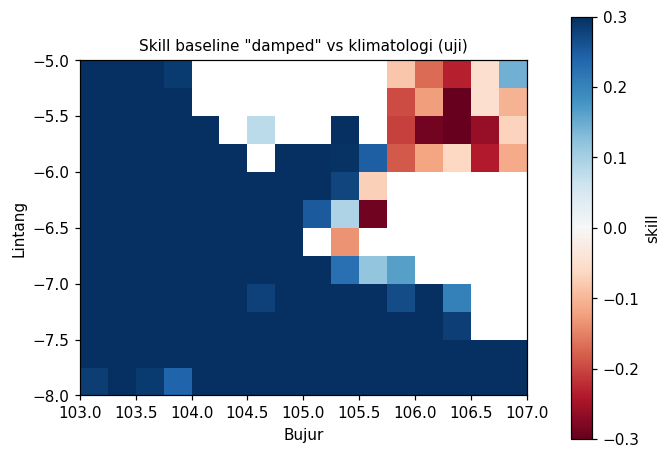

In [8]:
g = m.groupby('grid_id')
m['persist'] = g['y'].shift(H)
m['snaive'] = g['y'].shift(12)
m['a_lag'] = g['anom'].shift(H)
m['anom_persist'] = m.y_clim + m.a_lag
trn = m[(m.month <= TRAIN_END) & m.anom.notna() & m.a_lag.notna()]
rho = float((trn.anom * trn.a_lag).sum() / (trn.a_lag ** 2).sum())
m['damped'] = m.y_clim + rho * m.a_lag

BASE = ['y_clim', 'persist', 'snaive', 'anom_persist', 'damped']
test = m[(m.month > TRAIN_END) & m.y.notna()].dropna(subset=BASE)
mse_clim = ((test.y - test.y_clim) ** 2).mean()
res = pd.DataFrame({b: {'RMSE': np.sqrt(((test.y - test[b]) ** 2).mean()),
                        'MAE': (test.y - test[b]).abs().mean(),
                        'skill vs klimatologi': 1 - ((test.y - test[b]) ** 2).mean() / mse_clim}
                    for b in BASE}).T
print(f'rho (train) = {rho:.3f} | baris uji = {len(test):,} | horizon H = {H} bulan')
display(res.round(3))
save_table(res, 'baseline_skill')
score['rho_train'] = rho
score['rmse_clim'] = float(res.loc['y_clim', 'RMSE'])
score['skill_anom_persist'] = float(res.loc['anom_persist', 'skill vs klimatologi'])
score['skill_damped'] = float(res.loc['damped', 'skill vs klimatologi'])

# per grid dan per musim
per_grid = test.groupby('grid_id').apply(lambda d: 1 - ((d.y - d.damped) ** 2).mean() / ((d.y - d.y_clim) ** 2).mean())
season_map = {12: 'DJF', 1: 'DJF', 2: 'DJF', 3: 'MAM', 4: 'MAM', 5: 'MAM', 6: 'JJA', 7: 'JJA', 8: 'JJA', 9: 'SON', 10: 'SON', 11: 'SON'}
per_season = (test.assign(season=test.cal_month.map(season_map))
              .groupby('season').apply(lambda d: pd.Series({
                  'n': len(d), 'rmse_clim': np.sqrt(((d.y - d.y_clim) ** 2).mean()),
                  'skill_damped': 1 - ((d.y - d.damped) ** 2).mean() / ((d.y - d.y_clim) ** 2).mean()})))
display(per_season.round(3))

fig, ax = plt.subplots(figsize=(6, 4.6), constrained_layout=True)
grid_map(ax, per_grid, 'Skill baseline "damped" vs klimatologi (uji)', 'RdBu', 'skill', -.3, .3)
save_fig(fig, 'skill_damped_per_grid'); plt.show()

## 8. Struktur spasial anomali

Korelasi anomali antar grid terhadap jarak (ring 1 ≈ 28 km = tetangga langsung). Jika korelasi tetap tinggi sampai puluhan km, anomali bersifat koheren dan komponen spasial masuk akal. **Namun** jika PC1 menjelaskan sebagian besar varians, wilayah berperilaku seperti satu unit dan model spasial menambah sedikit informasi dibanding model per-wilayah.

,dist_km,r_mean,r_p25,r_p75,n_pairs
ring,,,,,
1,33.167,0.843,0.849,0.938,483
2,59.626,0.757,0.758,0.888,625
3,84.062,0.714,0.713,0.855,715
4,112.503,0.680,0.659,0.822,1176
5,142.160,0.638,0.604,0.788,880
6,168.560,0.596,0.522,0.756,1096
7,195.409,0.550,0.438,0.735,963
8,222.322,0.506,0.294,0.717,1053
9,250.994,0.447,0.157,0.699,1058


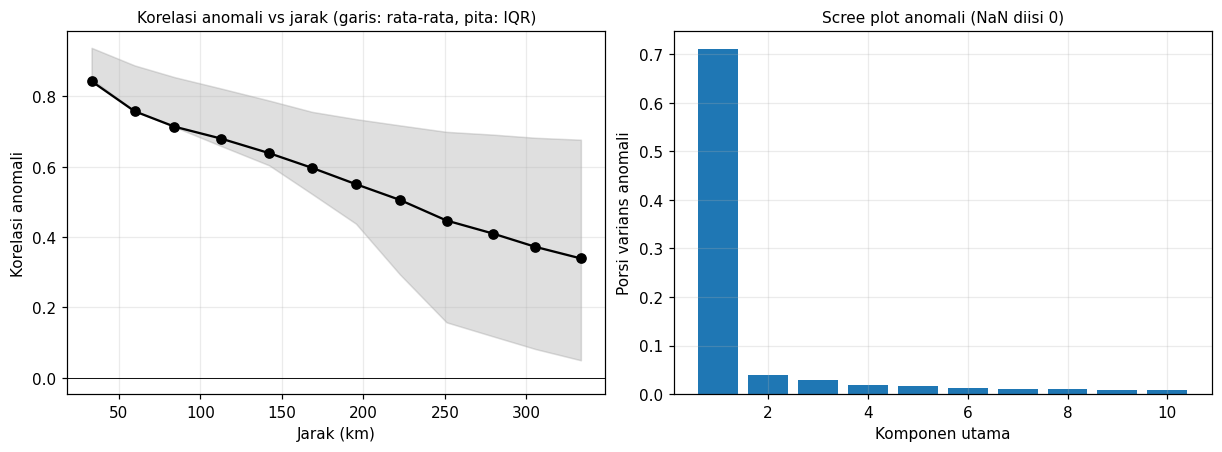

PC1 = 71.2%, PC2 = 4.0%, PC3 = 2.9%


In [9]:
C = A.corr(min_periods=60).to_numpy()
gi = grid_info.set_index('grid_id').loc[A.columns]
lat_r, lon_r = np.deg2rad(gi.lat.to_numpy()), np.deg2rad(gi.lon.to_numpy())
a_ = (np.sin((lat_r[:, None] - lat_r[None, :]) / 2) ** 2
      + np.cos(lat_r)[:, None] * np.cos(lat_r)[None, :] * np.sin((lon_r[:, None] - lon_r[None, :]) / 2) ** 2)
D = 2 * 6371 * np.arcsin(np.sqrt(a_))
iu = np.triu_indices_from(C, k=1)
ring = np.round(D[iu] / (GRID_DEG * 111.2)).astype(int)
sp = pd.DataFrame({'ring': ring, 'dist_km': D[iu], 'r': C[iu]}).dropna()
spb = (sp[sp.ring.between(1, 12)].groupby('ring')
       .agg(dist_km=('dist_km', 'mean'), r_mean=('r', 'mean'),
            r_p25=('r', lambda s: s.quantile(.25)), r_p75=('r', lambda s: s.quantile(.75)), n_pairs=('r', 'size')))
display(spb.round(3))
save_table(spb, 'korelasi_anomali_vs_jarak')

fig, axes = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
axes[0].plot(spb.dist_km, spb.r_mean, marker='o', color='black')
axes[0].fill_between(spb.dist_km, spb.r_p25, spb.r_p75, alpha=.25, color='gray')
axes[0].axhline(0, color='k', lw=.6); axes[0].set_xlabel('Jarak (km)'); axes[0].set_ylabel('Korelasi anomali')
axes[0].set_title('Korelasi anomali vs jarak (garis: rata-rata, pita: IQR)', fontsize=10)

Af = A.fillna(0).to_numpy(); Af = Af - Af.mean(axis=0)
sv = np.linalg.svd(Af, compute_uv=False); ev = sv ** 2 / (sv ** 2).sum()
axes[1].bar(range(1, 11), ev[:10]); axes[1].set_xlabel('Komponen utama'); axes[1].set_ylabel('Porsi varians anomali')
axes[1].set_title('Scree plot anomali (NaN diisi 0)', fontsize=10)
save_fig(fig, 'struktur_spasial_anomali'); plt.show()
print(f'PC1 = {ev[0]:.1%}, PC2 = {ev[1]:.1%}, PC3 = {ev[2]:.1%}')
for r_ in (1, 2, 4):
    if r_ in spb.index:
        score[f'corr_anom_ring{r_}_{int(round(spb.loc[r_, "dist_km"]))}km'] = float(spb.loc[r_, 'r_mean'])
score['pc1_share_anom'] = float(ev[0])

## 9. Struktur temporal anomali (autokorelasi)

Jika korelasi lag-1 anomali rendah, riwayat chl-a sendiri tidak banyak membantu memprediksi bulan berikutnya. Itu menentukan seberapa besar peran eksogen.

,median grid,p25,p75,regional
1,0.592,0.453,0.635,0.778
2,0.384,0.297,0.421,0.527
3,0.257,0.208,0.292,0.340
4,0.161,0.128,0.193,0.220
5,0.092,0.050,0.139,0.124
6,0.041,0.009,0.088,0.068
7,0.032,0.000,0.071,0.054
8,0.035,0.006,0.073,0.071
9,0.039,0.003,0.076,0.084
10,0.024,-0.019,0.071,0.056


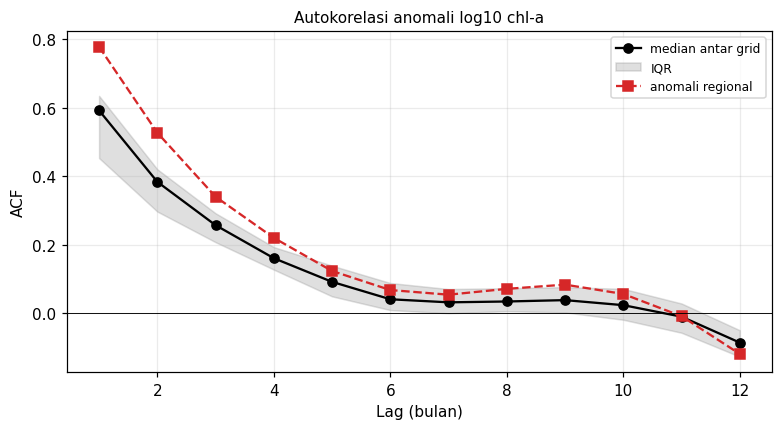

In [10]:
LAGS_ACF = list(range(1, 13))
acf = pd.DataFrame({lag: A.apply(lambda s: s.autocorr(lag)) for lag in LAGS_ACF})
reg_anom = A.mean(axis=1).where(A.notna().mean(axis=1) >= .5)
acf_reg = pd.Series({lag: reg_anom.autocorr(lag) for lag in LAGS_ACF})
acf_tab = pd.DataFrame({'median grid': acf.median(), 'p25': acf.quantile(.25), 'p75': acf.quantile(.75), 'regional': acf_reg})
display(acf_tab.round(3))
save_table(acf_tab, 'acf_anomali')

fig, ax = plt.subplots(figsize=(7, 3.8), constrained_layout=True)
ax.plot(LAGS_ACF, acf_tab['median grid'], marker='o', color='black', label='median antar grid')
ax.fill_between(LAGS_ACF, acf_tab.p25, acf_tab.p75, alpha=.25, color='gray', label='IQR')
ax.plot(LAGS_ACF, acf_tab.regional, marker='s', ls='--', color='tab:red', label='anomali regional')
ax.axhline(0, color='k', lw=.6); ax.set_xlabel('Lag (bulan)'); ax.set_ylabel('ACF'); ax.legend(fontsize=8)
ax.set_title('Autokorelasi anomali log10 chl-a', fontsize=10)
save_fig(fig, 'acf_anomali'); plt.show()
score['acf_lag1_median_grid'] = float(acf_tab.loc[1, 'median grid'])
score['acf_lag1_regional'] = float(acf_tab.loc[1, 'regional'])

## 10. Sinyal eksogen pada anomali

Dua perbandingan:

- **Regional, mentah vs anomali.** Korelasi nilai mentah dibesarkan oleh siklus musiman bersama. Korelasi anomali menunjukkan hubungan yang tersisa. `r_krit` memakai ukuran sampel efektif dari AR(1) (n × (1 − ρx·ρy)/(1 + ρx·ρy)).
- **Per grid, anomali.** Korelasi anomali chl-a(t) dengan anomali prediktor(t − lag). **Lag 0 hanya berguna untuk nowcasting**, bukan forecasting, kecuali nilai eksogen masa depan diketahui.

pearson        spearman        r_krit (anomali)
jenis          anomali mentah  anomali mentah                 
prediktor  lag                                                
Kec. angin 0     0.345  0.562    0.342  0.551            0.161
           1     0.369  0.542    0.357  0.487            0.158
           2     0.321  0.340    0.321  0.227            0.158
           3     0.297  0.097    0.276 -0.052            0.159
SST        0    -0.704 -0.750   -0.598 -0.504            0.223
           1    -0.661 -0.592   -0.560 -0.320            0.224
           2    -0.515 -0.280   -0.421 -0.022            0.223
           3    -0.363  0.020   -0.304  0.205            0.224
u10        0    -0.472 -0.601   -0.495 -0.733            0.168
           1    -0.355 -0.571   -0.388 -0.623            0.168
           2    -0.262 -0.436   -0.307 -0.384            0.168
           3    -0.230 -0.265   -0.229 -0.120            0.170
v10        0     0.570  0.664    0.575  0.711            0.183
           1     0.461  0.546    0.478  0.513            0.184
           2     0.368  0.358    0.387  0.253            0.182
           3     0.322  0.169    0.338  0.026            0.181

C:\Users\Rafi Adabhi Sunarya\AppData\Local\Temp\ipykernel_20872\92085422.py:30: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  r = tmp.groupby('grid_id').apply(lambda d: d.a.corr(d.x))
C:\Users\Rafi Adabhi Sunarya\AppData\Local\Temp\ipykernel_20872\92085422.py:30: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  r = tmp.groupby('grid_id').apply(lambda d: d.a.corr(d.x))
C:\Users\Rafi Adabhi Sunarya\AppData\Local\Temp\ipyk

prediktor,Kec. angin,SST,u10,v10
median r per grid (lag),,,,
0,0.299,-0.593,-0.383,0.452
1,0.307,-0.552,-0.303,0.380
2,0.261,-0.418,-0.217,0.300
3,0.242,-0.295,-0.196,0.251


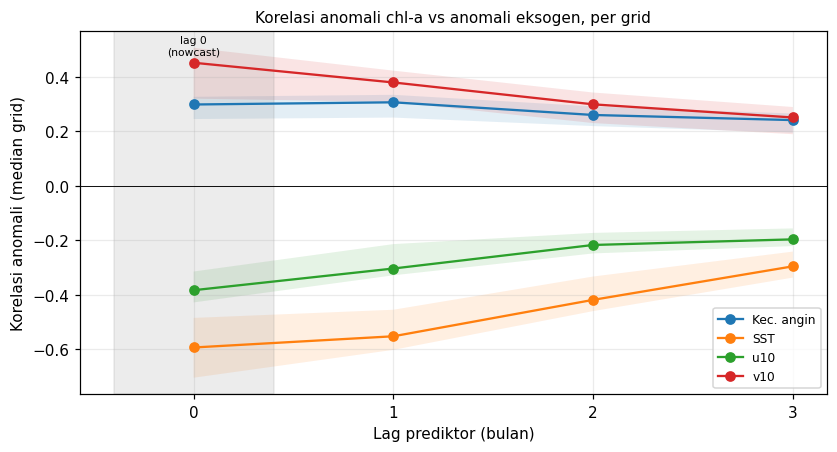

Pasangan terkuat untuk forecasting (lag >= 1): SST, lag 1, median r = -0.552


C:\Users\Rafi Adabhi Sunarya\AppData\Local\Temp\ipykernel_20872\92085422.py:54: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  rmap = pd.DataFrame({'grid_id': m.grid_id, 'a': m.anom, 'x': xs}).groupby('grid_id').apply(lambda d: d.a.corr(d.x))


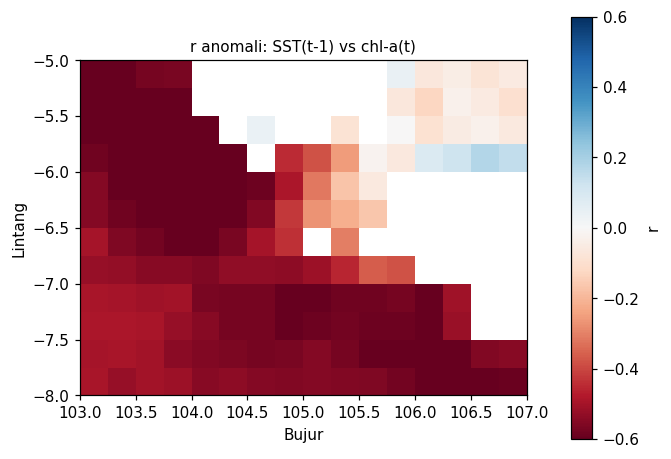

In [11]:
if not exog_ok:
    print('Panel eksogen tidak tersedia; bagian ini dilewati.')
else:
    reg_y = m.pivot(index='month', columns='grid_id', values='y')
    reg_y = reg_y.mean(axis=1).where(reg_y.notna().mean(axis=1) >= .5)

    rows = []
    for c, lab in EXOG.items():
        raw_x = m.pivot(index='month', columns='grid_id', values=c).mean(axis=1)
        an_x = m.pivot(index='month', columns='grid_id', values=f'{c}_anom').mean(axis=1)
        for lag in range(4):
            for kind, yy, xx in [('mentah', reg_y, raw_x), ('anomali', reg_anom, an_x)]:
                d_ = pd.DataFrame({'y': yy, 'x': xx.shift(lag)}).dropna()
                ry, rx = d_.y.autocorr(1), d_.x.autocorr(1)
                neff = len(d_) * (1 - ry * rx) / (1 + ry * rx)
                rows.append({'prediktor': lab, 'lag': lag, 'jenis': kind, 'pearson': d_.y.corr(d_.x),
                             'spearman': d_.y.corr(d_.x, method='spearman'), 'n': len(d_),
                             'n_eff': neff, 'r_krit': 1.96 / np.sqrt(max(neff, 3))})
    reg_tab = pd.DataFrame(rows)
    view = reg_tab.pivot_table(index=['prediktor', 'lag'], columns='jenis', values=['pearson', 'spearman'])
    view['r_krit (anomali)'] = reg_tab[reg_tab.jenis == 'anomali'].set_index(['prediktor', 'lag']).r_krit
    display(view.round(3))
    save_table(reg_tab, 'korelasi_regional_eksogen', index=False)

    rows = []
    for c, lab in EXOG.items():
        for lag in range(4):
            xs = m.groupby('grid_id')[f'{c}_anom'].shift(lag)
            tmp = pd.DataFrame({'grid_id': m.grid_id, 'a': m.anom, 'x': xs})
            r = tmp.groupby('grid_id').apply(lambda d: d.a.corr(d.x))
            rows.append(pd.DataFrame({'prediktor': lab, 'lag': lag, 'grid_id': r.index, 'r': r.values}))
    pg = pd.concat(rows, ignore_index=True)
    summ = pg.groupby(['prediktor', 'lag']).r.agg(median='median', p25=lambda s: s.quantile(.25),
                                                  p75=lambda s: s.quantile(.75),
                                                  share_abs_ge_03=lambda s: (s.abs() >= .3).mean()).reset_index()
    display(summ.pivot(index='lag', columns='prediktor', values='median').round(3).rename_axis('median r per grid (lag)'))
    save_table(summ, 'korelasi_per_grid_eksogen', index=False)

    fig, ax = plt.subplots(figsize=(7.5, 4), constrained_layout=True)
    for lab, d_ in summ.groupby('prediktor'):
        ax.plot(d_.lag, d_['median'], marker='o', label=lab)
        ax.fill_between(d_.lag, d_.p25, d_.p75, alpha=.12)
    ax.axhline(0, color='k', lw=.6); ax.axvspan(-.4, .4, color='gray', alpha=.15)
    ax.text(0, ax.get_ylim()[1] * .85, 'lag 0\n(nowcast)', ha='center', fontsize=7)
    ax.set_xticks(range(4)); ax.set_xlabel('Lag prediktor (bulan)'); ax.set_ylabel('Korelasi anomali (median grid)')
    ax.legend(fontsize=8); ax.set_title('Korelasi anomali chl-a vs anomali eksogen, per grid', fontsize=10)
    save_fig(fig, 'korelasi_eksogen_per_grid'); plt.show()

    cand = summ[summ.lag >= 1].assign(a=lambda d: d['median'].abs()).sort_values('a').iloc[-1]
    print(f'Pasangan terkuat untuk forecasting (lag >= 1): {cand.prediktor}, lag {int(cand.lag)}, median r = {cand["median"]:.3f}')
    score['eksogen_median_abs_r_terkuat_lag_ge1'] = float(cand.a)
    inv_map = {v: k for k, v in EXOG.items()}
    xs = m.groupby('grid_id')[f'{inv_map[cand.prediktor]}_anom'].shift(int(cand.lag))
    rmap = pd.DataFrame({'grid_id': m.grid_id, 'a': m.anom, 'x': xs}).groupby('grid_id').apply(lambda d: d.a.corr(d.x))
    fig, ax = plt.subplots(figsize=(6, 4.6), constrained_layout=True)
    grid_map(ax, rmap, f'r anomali: {cand.prediktor}(t-{int(cand.lag)}) vs chl-a(t)', 'RdBu', 'r', -.6, .6)
    save_fig(fig, 'peta_korelasi_eksogen'); plt.show()

## 11. Uji cepat: apakah eksogen menambah skill?

Regresi ridge pooled (semua grid) pada anomali, dengan split waktu yang sama. Dua model pada baris yang sama:

- **chl-only**: anomali chl-a lag `H` dan `H+1`
- **chl + eksogen**: ditambah anomali SST/u10/v10/angin pada lag `H`…`H+2`

Selisih keduanya mengisolasi kontribusi eksogen. Interval kepercayaan dihitung dengan block bootstrap pada bulan uji (blok 6 bulan). Ini bukan model akhir; tujuannya hanya mengecek apakah ada sinyal tambahan yang bisa diambil model sederhana.

In [12]:
if not exog_ok:
    print('Panel eksogen tidak tersedia; bagian ini dilewati.')
else:
    gg = m.groupby('grid_id')
    chl_feats = ['f_chl_1', 'f_chl_2']
    m['f_chl_1'] = gg['anom'].shift(H)
    m['f_chl_2'] = gg['anom'].shift(H + 1)
    exog_feats = []
    for c in EXOG:
        for lag in (H, H + 1, H + 2):
            name = f'f_{c}_{lag}'
            m[name] = gg[f'{c}_anom'].shift(lag)
            exog_feats.append(name)

    need = ['y', 'y_clim', 'anom', *chl_feats, *exog_feats]
    dm = m.dropna(subset=need).copy()
    tr, te = dm[dm.month <= TRAIN_END], dm[dm.month > TRAIN_END].copy()
    val_start = TRAIN_END - pd.DateOffset(years=3)

    def fit(df_fit, feats, alpha):
        mu, sd = df_fit[feats].mean(), df_fit[feats].std().replace(0, 1)
        X = np.c_[np.ones(len(df_fit)), ((df_fit[feats] - mu) / sd).to_numpy()]
        P = np.eye(X.shape[1]) * alpha; P[0, 0] = 0
        w = np.linalg.solve(X.T @ X + P, X.T @ df_fit.anom.to_numpy())
        return w, mu, sd

    def predict(df_new, feats, model):
        w, mu, sd = model
        return np.c_[np.ones(len(df_new)), ((df_new[feats] - mu) / sd).to_numpy()] @ w

    def run(feats):
        a_in, a_val = tr[tr.month <= val_start], tr[tr.month > val_start]
        best = min([1, 10, 100, 1000, 10000],
                   key=lambda al: ((a_val.anom - predict(a_val, feats, fit(a_in, feats, al))) ** 2).mean())
        return best, predict(te, feats, fit(tr, feats, best))

    al1, p1 = run(chl_feats)
    al2, p2 = run(chl_feats + exog_feats)
    te['p_chl'], te['p_exog'] = te.y_clim + p1, te.y_clim + p2

    mse_c = ((te.y - te.y_clim) ** 2).mean()
    mse_d = ((te.y - te.damped) ** 2).mean()
    models = {'klimatologi': te.y_clim, 'anom_persist': te.anom_persist, 'damped': te.damped,
              'ridge chl-only': te.p_chl, 'ridge chl + eksogen': te.p_exog}
    tab = pd.DataFrame({k: {'RMSE': np.sqrt(((te.y - v) ** 2).mean()),
                            'skill vs klimatologi': 1 - ((te.y - v) ** 2).mean() / mse_c,
                            'skill vs damped': 1 - ((te.y - v) ** 2).mean() / mse_d} for k, v in models.items()}).T
    print(f'Baris uji: {len(te):,} | alpha terpilih: chl-only={al1}, +eksogen={al2}')
    display(tab.round(3))
    save_table(tab, 'ridge_eksogen_skill')

    # kontribusi eksogen + CI block bootstrap pada bulan uji
    diff = (te.assign(d=(te.y - te.p_chl) ** 2 - (te.y - te.p_exog) ** 2).groupby('month').d.mean().to_numpy())
    rng, B, n = np.random.default_rng(42), 6, len(diff)
    boot = []
    for _ in range(2000):
        starts = rng.integers(0, max(n - B + 1, 1), size=int(np.ceil(n / B)))
        boot.append(np.concatenate([diff[s:s + B] for s in starts])[:n].mean())
    lo, hi = np.percentile(boot, [2.5, 97.5])
    gain = 1 - ((te.y - te.p_exog) ** 2).mean() / ((te.y - te.p_chl) ** 2).mean()
    print(f'Penurunan MSE karena eksogen: {gain:.1%} | selisih MSE rata-rata {diff.mean():.5f}, 95% CI [{lo:.5f}, {hi:.5f}]'
          f' -> {"CI di atas 0 (eksogen membantu)" if lo > 0 else "CI mencakup 0 (belum ada bukti eksogen membantu)"}')

    by_grp = te.groupby('grp').apply(lambda d: pd.Series({
        'n': len(d), 'skill_chl_only_vs_clim': 1 - ((d.y - d.p_chl) ** 2).mean() / ((d.y - d.y_clim) ** 2).mean(),
        'skill_eksogen_vs_clim': 1 - ((d.y - d.p_exog) ** 2).mean() / ((d.y - d.y_clim) ** 2).mean()}))
    display(by_grp.round(3))

    score['skill_ridge_chl_only'] = float(tab.loc['ridge chl-only', 'skill vs klimatologi'])
    score['skill_ridge_chl_eksogen'] = float(tab.loc['ridge chl + eksogen', 'skill vs klimatologi'])
    score['gain_mse_eksogen'] = float(gain)
    score['gain_mse_ci_lo'] = float(lo)
    score['gain_mse_ci_hi'] = float(hi)

Baris uji: 10,738 | alpha terpilih: chl-only=1, +eksogen=10000


,RMSE,skill vs klimatologi,skill vs damped
klimatologi,0.314,0.000,-0.845
anom_persist,0.241,0.411,-0.087
damped,0.231,0.458,0.000
ridge chl-only,0.230,0.465,0.013
ridge chl + eksogen,0.233,0.449,-0.016


Penurunan MSE karena eksogen: -2.9% | selisih MSE rata-rata -0.00176, 95% CI [-0.01188, 0.00436] -> CI mencakup 0 (belum ada bukti eksogen membantu)


C:\Users\Rafi Adabhi Sunarya\AppData\Local\Temp\ipykernel_20872\3143130433.py:64: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  by_grp = te.groupby('grp').apply(lambda d: pd.Series({
C:\Users\Rafi Adabhi Sunarya\AppData\Local\Temp\ipykernel_20872\3143130433.py:64: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  by_grp = te.groupby('grp').apply(lambda d: pd.Series({


,n,skill_chl_only_vs_clim,skill_eksogen_vs_clim
grp,,,
chl-a rendah,3651.0,0.485,0.466
chl-a menengah,3662.0,0.505,0.482
chl-a tinggi,3425.0,0.331,0.341


## 12. Scorecard

Ringkasan angka kunci untuk satu lokasi. Jalankan notebook ini lagi untuk Laut Jawa barat (ubah `REGION`, `TAG`, jalur file), lalu gabungkan kedua CSV scorecard untuk membandingkan keduanya dengan ukuran yang sama.

In [13]:
score_df = pd.Series({'n_grid': m.grid_id.nunique(), 'n_bulan': m.month.nunique(), **score}, name=REGION).to_frame()
display(score_df.round(3))
score_df.to_csv(TABLE_DIR / f'scorecard_{REGION}_{TAG}.csv', encoding='utf-8-sig')

# Gabung dengan lokasi lain bila file scorecard-nya ada
others = [p for p in TABLE_DIR.glob(f'scorecard_*_{TAG}.csv') if p.stem != f'scorecard_{REGION}_{TAG}']
if others:
    comp = pd.concat([score_df] + [pd.read_csv(p, index_col=0, encoding='utf-8-sig') for p in others], axis=1)
    display(comp.round(3))

,selat_sunda
n_grid,148.000
n_bulan,276.000
avail_ge1px,0.972
avail_ge50pct_px,0.916
avail_reliable,0.950
n_bulan_avail_lt90,24.000
var_antar_grid,0.485
var_musiman,0.160
var_anomali,0.355
std_anomali_log10,0.249
